# Исполнение консолидированных бюджетов субъектов РФ: примеры запросов и визуализаций

Тетрадка показывает, как работать с базой `data/db/roskazna_kbs.duckdb`, собранной из
отчётов Федерального казначейства (ф. 0503317, 0503320, 0503321, 0503323; до 2005 г. — ф. 0524100).
Схема БД — [database.md](database.md), содержание исходных файлов — [files.md](files.md),
покрытие по годам — [coverage.md](coverage.md).

**Как запустить.** Соберите БД (`python -m roskazna_kbs build`), установите зависимости
(`uv pip install -e ".[notebook]"`) и откройте тетрадку из каталога `docs/`:

```bash
jupyter lab docs/examples.ipynb
```

Все суммы в БД — в рублях; в тетрадке они переводятся в млрд или трлн руб. Срез «на 1 января»
содержит итоги прошлого года (`period_months = 12`), срез на 1 сентября — 8 месяцев текущего года.

Содержание:

1. Что в базе
2. Доходы, расходы и дефицит консолидированных бюджетов субъектов, 2005–2025
3. Исполнение внутри года
4. Регионы: крупнейшие бюджеты и сбалансированность
5. Структура доходов
6. Структура расходов по разделам
7. Уровни бюджетной системы
8. Федеральные округа («шахматки»)
9. Межбюджетные трансферты из бюджета субъекта
10. Сравнение регионов-лидеров
11. Данные до 2005 года
12. Проверки качества и происхождение цифр
13. Те же данные из Parquet

In [1]:
import textwrap
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
DB = ROOT / "data" / "db" / "roskazna_kbs.duckdb"
con = duckdb.connect(str(DB), read_only=True)
con.sql("SET enable_progress_bar = false")


def q(sql: str) -> pd.DataFrame:
    """SQL → pandas.DataFrame."""
    return con.sql(sql).df()


pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.1f}".replace(",", " "))

In [2]:
# Оформление графиков: справочная палитра (категориальные цвета в фиксированном порядке,
# одна шкала синего для упорядоченных рядов, пара синий/красный для «профицит/дефицит»).
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
ORDINAL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # от раннего к позднему
POS, NEG = "#2a78d6", "#e34948"                                       # профицит / дефицит
TEXT, TEXT2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.figsize": (10, 5), "figure.dpi": 110,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "text.color": TEXT, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.axisbelow": True, "lines.linewidth": 2, "lines.markersize": 5, "legend.frameon": False,
})


def fmt_axis(ax, unit: str = "") -> None:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ") + unit))


def end_labels(ax, items, min_gap=0.05):
    """Подписи в конце линий (для ≤ 4 рядов): items = [(x, y, text)].
    Подписи раздвигаются по вертикали, чтобы не налезать друг на друга."""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap
    placed = []
    for x, y, text in sorted(items, key=lambda t: t[1]):
        ty = max(y, placed[-1] + gap) if placed else y
        placed.append(ty)
        ax.text(x, ty, text, va="center", fontsize=9, color=TEXT2, clip_on=False)

## 1. Что в базе

Основные таблицы: `report` — отчёт (книга формы по территории на дату), `line` → `indicator` —
строки формы и показатели, `value` — значения граф (показатель `measure`, уровень бюджета
`budget_level`), `chess_value` — итоги по РФ и федеральным округам. Витрины `v_*` соединяют их.

In [3]:
q("""
SELECT 'пакетов' AS what, count(*) AS n FROM source_file UNION ALL
SELECT 'файлов в пакетах', count(*) FROM archive_member UNION ALL
SELECT 'отчётов', count(*) FROM report UNION ALL
SELECT 'показателей', count(*) FROM indicator UNION ALL
SELECT 'строк отчётов', count(*) FROM line UNION ALL
SELECT 'значений', count(*) FROM value UNION ALL
SELECT 'значений «шахматок»', count(*) FROM chess_value
""")

,what,n
0,пакетов,338
1,файлов в пакетах,62612
2,отчётов,36156
3,показателей,141260
4,строк отчётов,53647644
5,значений,353211852
6,значений «шахматок»,34210595


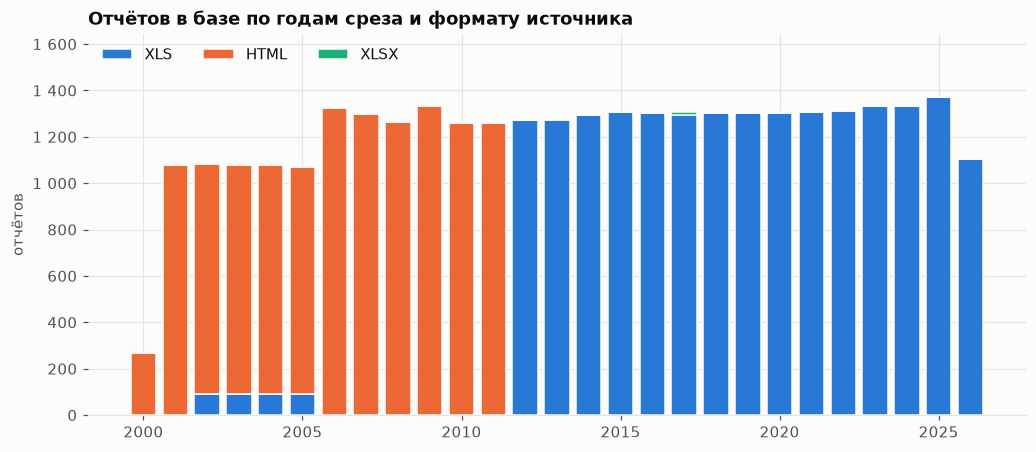

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
source_format,,,,,,,,,,,,,,,,,,,,,
xls,0,0,90,90,90,90,0,0,0,0,...,1293,1301,1301,1304,1305,1313,1331,1332,1370,1104
html,268,1080,991,990,990,979,1326,1297,1265,1333,...,0,0,0,1,0,1,0,0,0,0
xlsx,0,0,0,0,0,0,0,0,0,0,...,12,4,4,0,0,0,1,3,0,0


In [4]:
cov = q("""
SELECT year(report_date) AS year, source_format, count(*) AS reports
FROM v_report WHERE is_preferred
GROUP BY ALL ORDER BY 1
""").pivot(index="year", columns="source_format", values="reports").fillna(0)
cov = cov[[c for c in ["xls", "html", "xlsx"] if c in cov]]

fig, ax = plt.subplots(figsize=(11, 4.5))
bottom = None
for i, col in enumerate(cov.columns):
    ax.bar(cov.index, cov[col], bottom=bottom, color=SERIES[i], width=0.8, label=col.upper(),
           edgecolor=SURFACE, linewidth=1)
    bottom = cov[col] if bottom is None else bottom + cov[col]
ax.set_title("Отчётов в базе по годам среза и формату источника")
ax.set_ylabel("отчётов")
ax.set_ylim(0, cov.sum(axis=1).max() * 1.2)
ax.legend(loc="upper left", ncols=3)
fmt_axis(ax)
plt.show()
cov.astype(int).T

До 2011 г. большинство отчётов есть только в HTML-версии (в 2000–2004 гг. — ещё и XLS формы
0524100), с 2012 г. — в Excel. Всплеск в 2007 г.: годовой пакет за 2007 г. содержит все месячные
отчёты года, а витрина `v_report` (признак `is_preferred`) оставляет по одному отчёту на территорию и дату.

## 2. Доходы, расходы и дефицит, 2005–2025

Витрина `v_0503317_totals` — итоговые строки формы 0503317 по каждой территории и дате
(консолидированный бюджет субъекта и ТГВФ). Годовые итоги — срез на 1 января (`period_months = 12`).
Сумма по субъектам (без свода, код 95) доступна за все годы с 2005 г.; свод по РФ — с 2012 г.

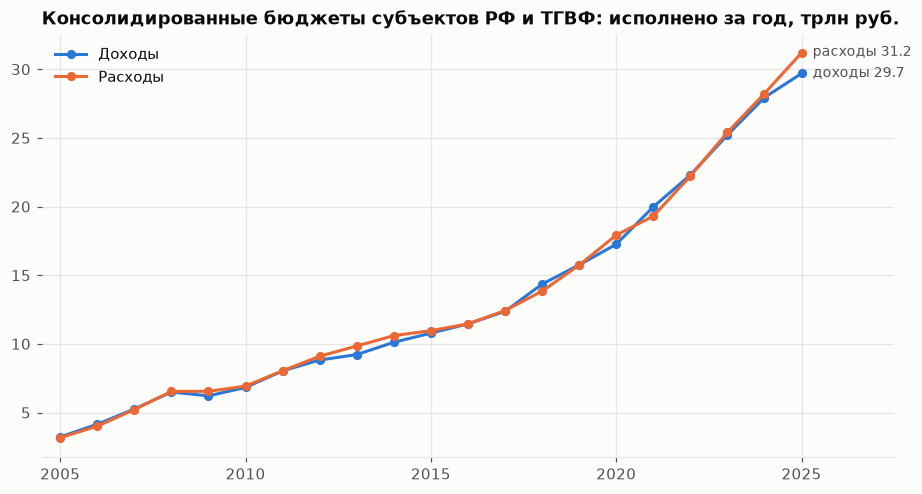

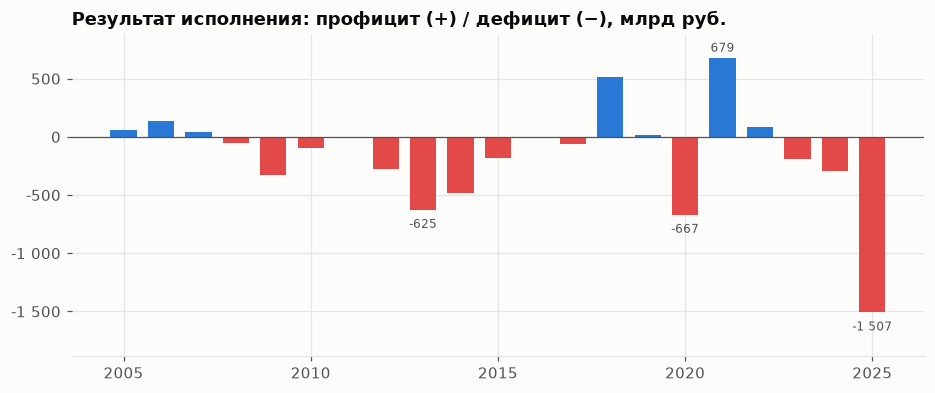

,year,income,expense,result_bn,territories
0,2005,3.2,3.2,61.4,89
1,2006,4.1,4.0,139.3,89
2,2007,5.3,5.2,42.7,86
3,2008,6.5,6.5,-48.7,84
4,2009,6.2,6.5,-328.4,84
5,2010,6.8,6.9,-98.8,84
6,2011,8.0,8.0,-14.0,84
7,2012,8.8,9.1,-273.3,84
8,2013,9.2,9.8,-625.0,84
9,2014,10.1,10.6,-485.4,86


In [5]:
tot = q("""
SELECT period_year AS year,
       sum(income_executed)  / 1e12 AS income,
       sum(expense_executed) / 1e12 AS expense,
       sum(result_executed)  / 1e9  AS result_bn,
       count(*) AS territories
FROM v_0503317_totals
WHERE period_months = 12 AND territory_code <> '95'
GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots()
ax.plot(tot.year, tot.income, color=SERIES[0], marker="o", label="Доходы")
ax.plot(tot.year, tot.expense, color=SERIES[1], marker="o", label="Расходы")
last = tot.iloc[-1]
end_labels(ax, [(last.year + 0.3, last.income, f"доходы {last.income:.1f}"),
                (last.year + 0.3, last.expense, f"расходы {last.expense:.1f}")])
ax.set_title("Консолидированные бюджеты субъектов РФ и ТГВФ: исполнено за год, трлн руб.")
ax.set_xlim(tot.year.min() - 0.5, tot.year.max() + 2.5)
ax.legend(loc="upper left")
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(tot.year, tot.result_bn, color=[POS if v >= 0 else NEG for v in tot.result_bn], width=0.7)
ax.axhline(0, color=TEXT2, linewidth=0.8)
ax.set_ylim(tot.result_bn.min() * 1.25, max(tot.result_bn.max() * 1.3, 100))
ax.set_title("Результат исполнения: профицит (+) / дефицит (−), млрд руб.")
fmt_axis(ax)
for x, v in zip(tot.year, tot.result_bn):
    if abs(v) > 600:
        ax.annotate(f"{v:,.0f}".replace(",", " "), (x, v), xytext=(0, 4 if v > 0 else -12),
                    textcoords="offset points", ha="center", fontsize=8, color=TEXT2)
plt.show()
tot

Доходы и расходы — на одной оси в одних единицах; результат исполнения (на два порядка меньше)
вынесен на отдельный график, чтобы не вводить вторую ось.

## 3. Исполнение внутри года

Месячные срезы — нарастающим итогом с начала года. Отношение исполнения к утверждённым годовым
назначениям показывает, как распределяется исполнение по месяцам. Используется сводный отчёт по РФ
(код 95); на 01.10.2024 свода в источнике нет — точка пропущена.

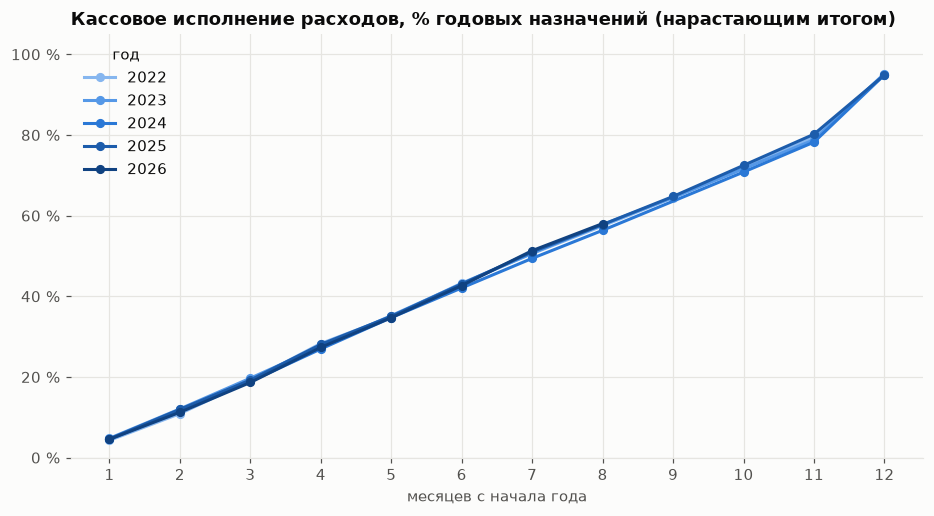

year,2022,2023,2024,2025,2026
months,,,,,
1,4.3,4.8,4.5,4.6,4.6
2,10.9,12.1,11.7,12.0,11.3
3,19.1,19.7,18.9,19.2,18.6
4,28.3,27.6,26.9,28.1,27.3
5,34.9,35.2,34.7,35.0,34.7
6,43.3,43.1,42.1,43.0,42.7
7,50.6,50.7,49.4,51.0,51.3
8,57.5,57.8,56.4,57.8,58.0
9,64.5,64.5,NaN,64.8,NaN


In [6]:
mon = q("""
SELECT period_year AS year, period_months AS months,
       100 * expense_executed / expense_approved AS expense_pct,
       100 * income_executed  / income_approved  AS income_pct
FROM v_0503317_totals
WHERE territory_code = '95' AND period_year BETWEEN 2022 AND 2026
ORDER BY 1, 2
""")

fig, ax = plt.subplots()
for color, (year, g) in zip(ORDINAL, mon.groupby("year")):
    ax.plot(g.months, g.expense_pct, color=color, marker="o", label=str(year))
ax.set_xticks(range(1, 13))
ax.set_xlabel("месяцев с начала года")
ax.set_ylim(0, 105)
fmt_axis(ax, " %")
ax.set_title("Кассовое исполнение расходов, % годовых назначений (нарастающим итогом)")
ax.legend(title="год", loc="upper left")
plt.show()
mon.pivot(index="months", columns="year", values="expense_pct")

## 4. Регионы: крупнейшие бюджеты и сбалансированность

Отчёт каждой территории — консолидированный бюджет субъекта (бюджет субъекта + местные бюджеты)
и бюджет ТГВФ. Наименования — из справочника `territory`.

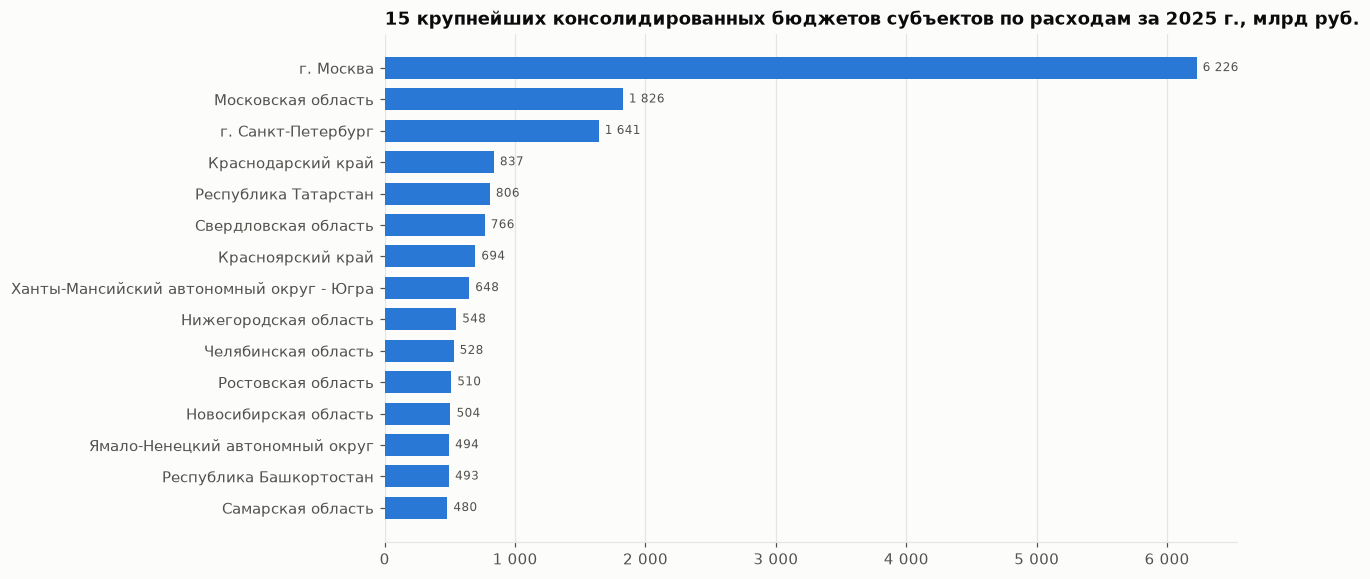

,territory_code,territory_name,expense_bn,income_bn,result_pct
0,73,г. Москва,6 226.2,5 988.9,-4.0
1,48,Московская область,1 825.6,1 810.3,-0.8
2,72,г. Санкт-Петербург,1 640.8,1 577.7,-4.0
3,18,Краснодарский край,836.7,796.7,-5.0
4,11,Республика Татарстан,805.7,806.6,0.1
5,62,Свердловская область,766.5,721.5,-6.2
6,19,Красноярский край,694.3,653.8,-6.2
7,87,Ханты-Мансийский автономный округ - Югра,647.6,577.9,-12.1
8,32,Нижегородская область,547.6,480.4,-14.0
9,69,Челябинская область,527.9,456.0,-15.8


In [7]:
reg = q("""
SELECT territory_code, territory_name,
       expense_executed / 1e9 AS expense_bn,
       income_executed  / 1e9 AS income_bn,
       100 * result_executed / income_executed AS result_pct
FROM v_0503317_totals
WHERE report_date = DATE '2026-01-01' AND territory_code NOT IN ('95')
ORDER BY expense_executed DESC
""")

top = reg.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.territory_name, top.expense_bn, color=SERIES[0], height=0.7)
for y, v in enumerate(top.expense_bn):
    ax.annotate(f"{v:,.0f}".replace(",", " "), (v, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=TEXT2)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set_title("15 крупнейших консолидированных бюджетов субъектов по расходам за 2025 г., млрд руб.")
plt.show()
reg.head(15)

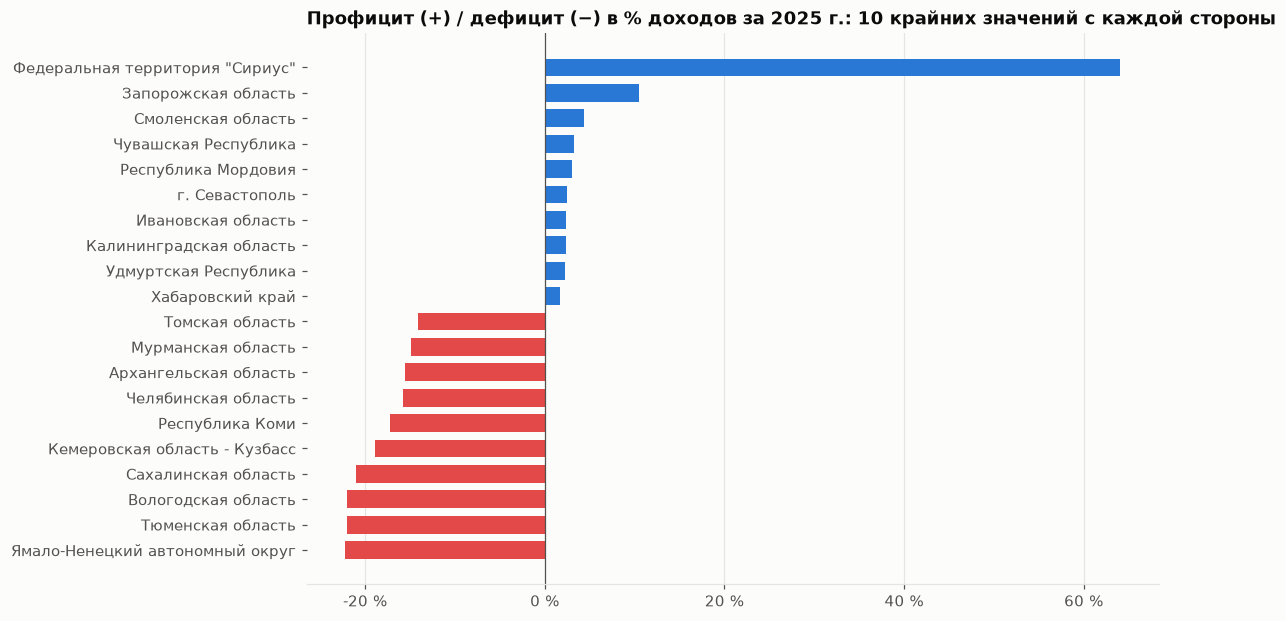

,territory_name,income_bn,expense_bn,result_pct
12,Ямало-Ненецкий автономный округ,404.0,493.6,-22.2
19,Тюменская область,323.7,394.9,-22.0
38,Вологодская область,182.6,222.7,-22.0
26,Сахалинская область,254.7,308.1,-21.0
20,Кемеровская область - Кузбасс,325.0,386.4,-18.9
50,Республика Коми,156.0,182.9,-17.3
9,Челябинская область,456.0,527.9,-15.8
37,Архангельская область,198.6,229.5,-15.6
42,Мурманская область,183.1,210.4,-14.9
51,Томская область,158.4,180.8,-14.1


In [8]:
bal = pd.concat([reg.nsmallest(10, "result_pct"), reg.nlargest(10, "result_pct")]).sort_values("result_pct")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(bal.territory_name, bal.result_pct, color=[POS if v >= 0 else NEG for v in bal.result_pct], height=0.7)
ax.axvline(0, color=TEXT2, linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_title("Профицит (+) / дефицит (−) в % доходов за 2025 г.: 10 крайних значений с каждой стороны")
plt.show()
bal[["territory_name", "income_bn", "expense_bn", "result_pct"]]

## 5. Структура доходов

Доходы по кодам бюджетной классификации (17 знаков без главы, `indicator.kbk_code`), свод по РФ,
консолидированный бюджет субъектов и ТГВФ, исполнено за год.

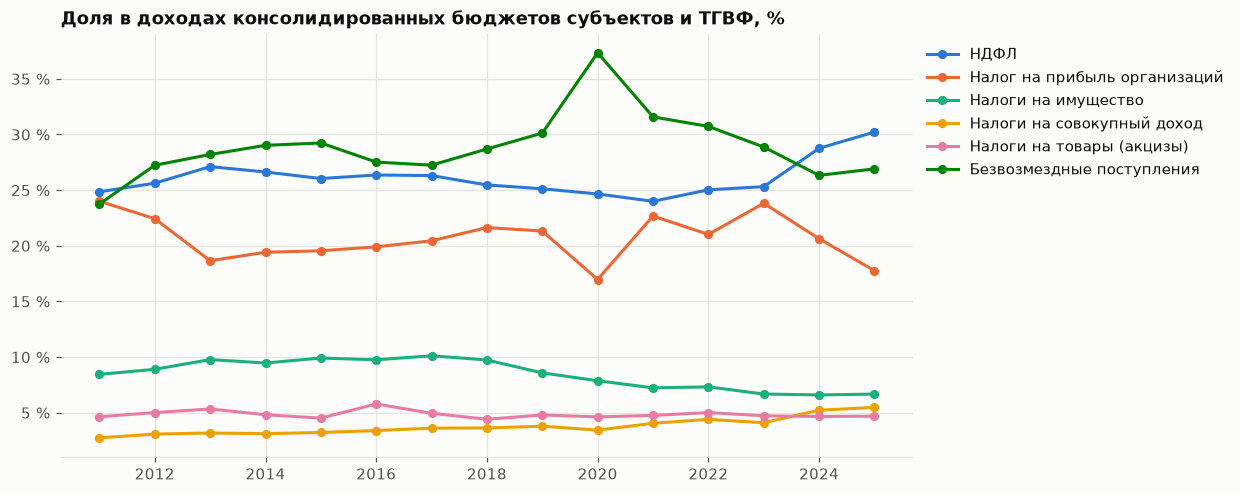

kbk_code,НДФЛ,Налог на прибыль организаций,Налоги на имущество,Налоги на совокупный доход,Налоги на товары (акцизы),Безвозмездные поступления
year,,,,,,
2011,24.8,24.0,8.4,2.7,4.6,23.8
2012,25.6,22.4,8.9,3.1,5.0,27.2
2013,27.1,18.7,9.8,3.2,5.3,28.2
2014,26.6,19.4,9.5,3.1,4.8,29.0
2015,26.0,19.5,9.9,3.2,4.5,29.2
2016,26.4,19.9,9.8,3.4,5.8,27.5
2017,26.3,20.4,10.1,3.6,5.0,27.2
2018,25.5,21.6,9.7,3.6,4.4,28.7
2019,25.1,21.3,8.6,3.8,4.8,30.1


In [9]:
KBK = {
    "10102000010000110": "НДФЛ",
    "10101000000000110": "Налог на прибыль организаций",
    "10600000000000000": "Налоги на имущество",
    "10500000000000000": "Налоги на совокупный доход",
    "10300000000000000": "Налоги на товары (акцизы)",
    "20000000000000000": "Безвозмездные поступления",
}
inc = q(f"""
SELECT v.period_year AS year, v.kbk_code, sum(v.value) AS value, any_value(t.income_executed) AS total
FROM v_value v
JOIN v_0503317_totals t USING (report_id)
WHERE v.territory_code = '95' AND v.is_preferred AND v.period_months = 12 AND v.section = 'income'
  AND v.measure = 'executed' AND v.budget_level = 'cons_subject_tgvf'
  AND v.kbk_code IN ({", ".join(repr(k) for k in KBK)})
GROUP BY ALL ORDER BY 1
""")
inc["share"] = 100 * inc.value / inc.total
shares = inc.pivot(index="year", columns="kbk_code", values="share")[list(KBK)].rename(columns=KBK)

fig, ax = plt.subplots()
for i, col in enumerate(shares.columns):
    ax.plot(shares.index, shares[col], color=SERIES[i], marker="o", label=col)
fmt_axis(ax, " %")
ax.set_title("Доля в доходах консолидированных бюджетов субъектов и ТГВФ, %")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()
shares

## 6. Структура расходов по разделам

Строки раздела расходов уровня «раздел» (Рз/Пр вида `XX00`, без целевой статьи и вида расходов),
свод по РФ: сравнение 2015 и 2025 гг. в долях от суммы разделов.

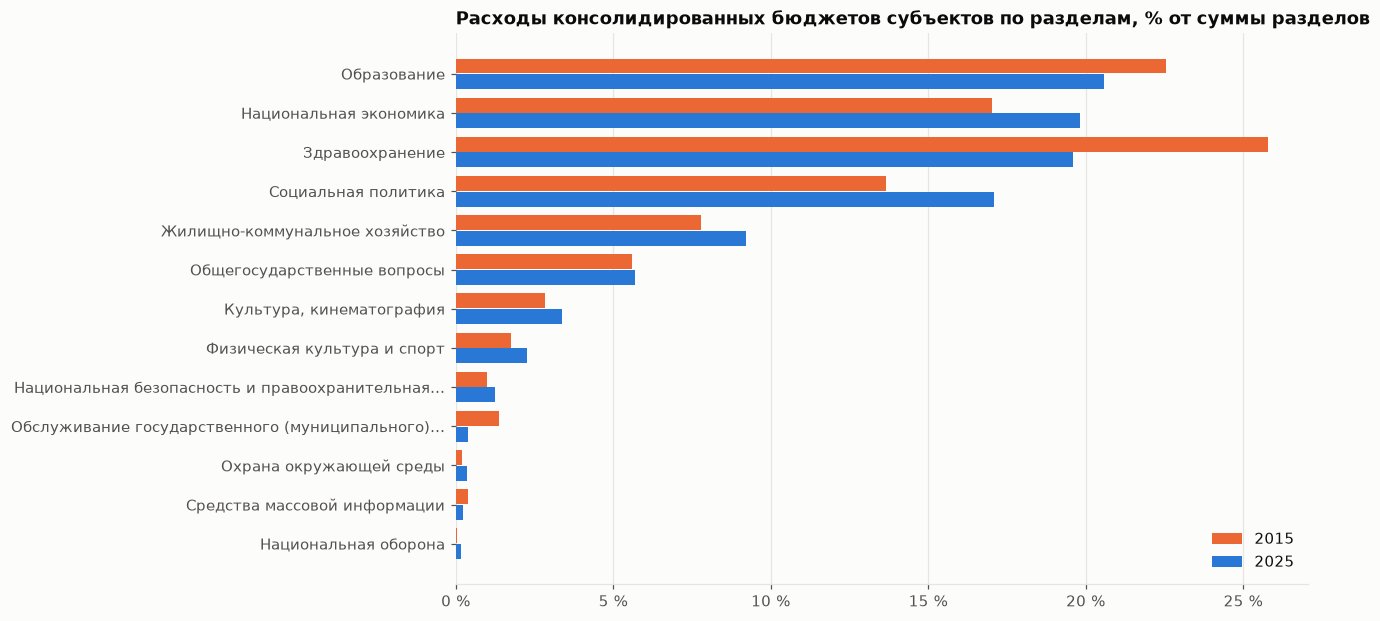

year,2015,2025
name,,
Образование,2 472.5,6 418.6
Национальная экономика,1 866.0,6 179.4
Здравоохранение,2 825.1,6 114.0
Социальная политика,1 496.4,5 331.4
Жилищно-коммунальное хозяйство,854.9,2 870.8
Общегосударственные вопросы,615.1,1 777.2
"Культура, кинематография",310.6,1 049.4
Физическая культура и спорт,193.1,703.5
Национальная безопасность и правоохранительная деятельность,107.6,392.8


In [10]:
sec = q("""
SELECT period_year AS year, rzpr_code, any_value(name) AS name, sum(value) / 1e9 AS bn
FROM v_value
WHERE territory_code = '95' AND is_preferred AND period_months = 12 AND section = 'expense'
  AND measure = 'executed' AND budget_level = 'cons_subject_tgvf'
  AND rzpr_code LIKE '__00' AND rzpr_code NOT IN ('9600', '7900', '9700')
  AND coalesce(csr_code, '0') ~ '^0+$' AND coalesce(vr_code, '000') = '000'
  AND period_year IN (2015, 2025)
GROUP BY ALL
""")
sec["share"] = 100 * sec.bn / sec.groupby("year").bn.transform("sum")
names = sec[sec.year == 2025].set_index("rzpr_code").name
w = sec.pivot(index="rzpr_code", columns="year", values="share").fillna(0)
w = w[w.max(axis=1) >= 0.1].sort_values(2025)
w.index = [textwrap.shorten(names.get(c, c), 48, placeholder="…") for c in w.index]

fig, ax = plt.subplots(figsize=(10, 6.5))
y = range(len(w))
ax.barh([i + 0.2 for i in y], w[2015], height=0.38, color=SERIES[1], label="2015")
ax.barh([i - 0.2 for i in y], w[2025], height=0.38, color=SERIES[0], label="2025")
ax.set_yticks(list(y), w.index)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_title("Расходы консолидированных бюджетов субъектов по разделам, % от суммы разделов")
ax.legend(loc="lower right")
plt.show()
sec.pivot(index="name", columns="year", values="bn").sort_values(2025, ascending=False)

## 7. Уровни бюджетной системы

В отчёте каждая сумма раскладывается по уровням бюджета (`budget_level`): бюджет субъекта,
городские округа, муниципальные районы, поселения и т. д. Консолидированный бюджет — их сумма
за вычетом взаимных расчётов (графы «суммы, подлежащие исключению»). Ниже — доли уровней в
исполненных расходах (до исключения), свод по РФ. Набор уровней менялся (с 2016 г. поселения
отчитываются раздельно, с 2020 г. появились муниципальные округа), поэтому уровни сгруппированы.
В отчёте за 2021 г. муниципальные и городские округа даны одной графой («бюджеты муниципальных
округов, городских округов», уровень `municipal_city_okrug`) — она попадает в группу
«Муниципальные округа», отсюда провал городских округов в 2021 г.

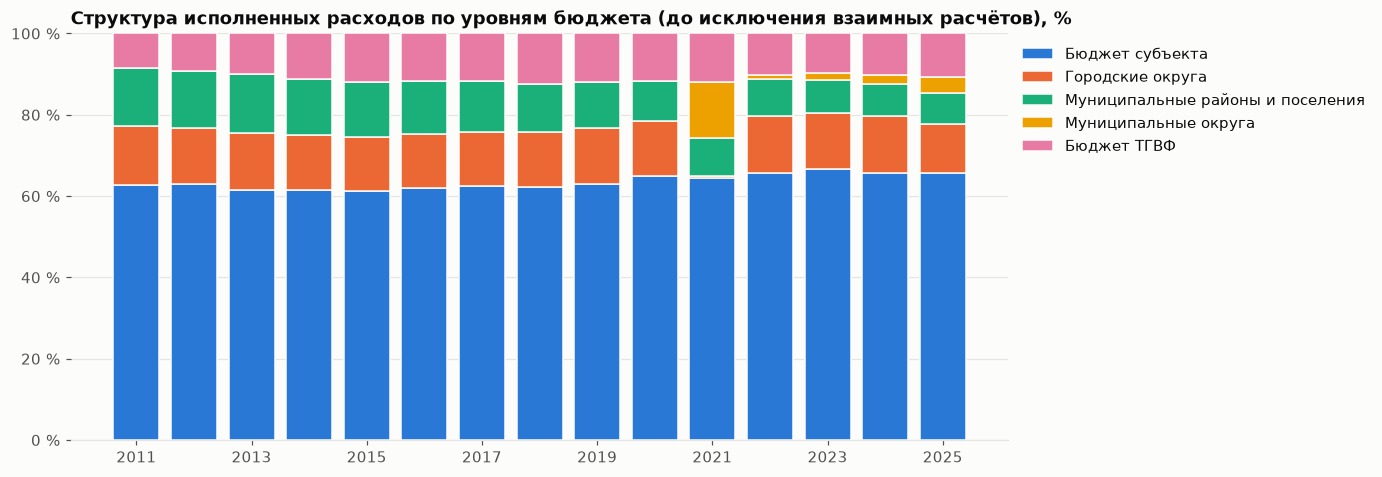

group,Бюджет субъекта,Городские округа,Муниципальные районы и поселения,Муниципальные округа,Бюджет ТГВФ
year,,,,,
2011,62.7,14.5,14.3,0.0,8.5
2012,62.9,13.8,14.2,0.0,9.2
2013,61.6,13.9,14.5,0.0,10.0
2014,61.5,13.4,13.9,0.0,11.1
2015,61.2,13.2,13.6,0.0,12.0
2016,61.9,13.3,13.0,0.0,11.7
2017,62.5,13.2,12.7,0.0,11.6
2018,62.3,13.4,11.9,0.0,12.4
2019,63.0,13.8,11.2,0.0,12.0


In [11]:
GROUPS = {
    "subject": "Бюджет субъекта",
    "city_okrug": "Городские округа", "city_okrug_div": "Городские округа",
    "intracity_district": "Городские округа", "intracity_mo": "Городские округа",
    "municipal_okrug": "Муниципальные округа", "municipal_city_okrug": "Муниципальные округа",
    "municipal_district": "Муниципальные районы и поселения", "settlement": "Муниципальные районы и поселения",
    "urban_settlement": "Муниципальные районы и поселения", "rural_settlement": "Муниципальные районы и поселения",
    "tgvf": "Бюджет ТГВФ",
}
lv = q("""
SELECT period_year AS year, budget_level, sum(value) AS value
FROM v_value
WHERE territory_code = '95' AND is_preferred AND period_months = 12 AND section = 'expense'
  AND measure = 'executed' AND is_total_marker AND name ILIKE 'расходы%'
GROUP BY ALL
""")
lv["group"] = lv.budget_level.map(GROUPS)
lv = lv.dropna(subset=["group"]).groupby(["year", "group"]).value.sum().unstack().fillna(0)
order = ["Бюджет субъекта", "Городские округа", "Муниципальные районы и поселения", "Муниципальные округа", "Бюджет ТГВФ"]
lv = lv[[c for c in order if c in lv]]
pct = 100 * lv.div(lv.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(11, 4.8))
bottom = 0
for i, col in enumerate(pct.columns):
    ax.bar(pct.index, pct[col], bottom=bottom, color=SERIES[i], width=0.8, label=col, edgecolor=SURFACE, linewidth=1)
    bottom = bottom + pct[col]
ax.set_ylim(0, 100)
ax.set_xticks(pct.index[::2])
fmt_axis(ax, " %")
ax.set_title("Структура исполненных расходов по уровням бюджета (до исключения взаимных расчётов), %")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()
pct

## 8. Федеральные округа («шахматки»)

Итоги по РФ и федеральным округам на месячных срезах есть только в сводных книгах «по графам»
(таблица `chess_value`, витрина `v_chess`). Показатель `010 *** 85000000000000000` — «Доходы бюджета — итого».

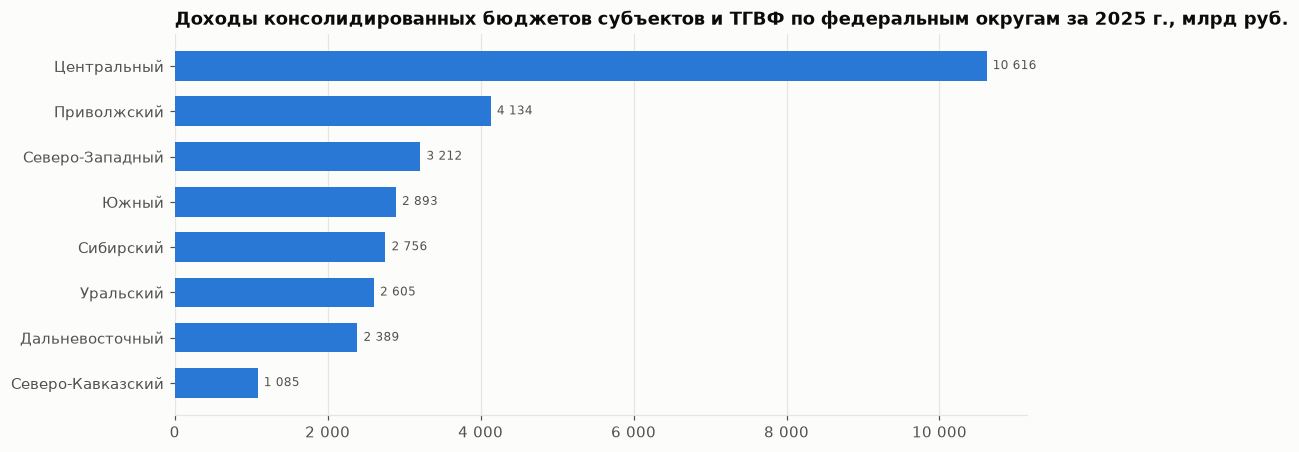

,territory_name,income_bn
7,Центральный федеральный округ,10 616.5
6,Приволжский федеральный округ,4 133.5
5,Северо-Западный федеральный округ,3 212.2
4,Южный федеральный округ,2 892.7
3,Сибирский федеральный округ,2 755.6
2,Уральский федеральный округ,2 605.4
1,Дальневосточный федеральный округ,2 388.8
0,Северо-Кавказский федеральный округ,1 085.5


In [12]:
fo = q("""
SELECT territory_name, sum(value) / 1e9 AS income_bn
FROM v_chess
WHERE is_preferred AND report_date = DATE '2026-01-01' AND section = 'income'
  AND budget_level = 'cons_subject_tgvf' AND territory_kind = 'okrug'
  AND indicator_code LIKE '010 ***%'
GROUP BY 1 ORDER BY 2
""")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(fo.territory_name.str.replace(" федеральный округ", ""), fo.income_bn, color=SERIES[0], height=0.65)
for y, v in enumerate(fo.income_bn):
    ax.annotate(f"{v:,.0f}".replace(",", " "), (v, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=TEXT2)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set_title("Доходы консолидированных бюджетов субъектов и ТГВФ по федеральным округам за 2025 г., млрд руб.")
plt.show()
fo.sort_values("income_bn", ascending=False)

## 9. Межбюджетные трансферты из бюджета субъекта

Раздел 4 формы 0503317 — таблица консолидируемых расчётов: строки — бюджет-отправитель и вид
выбытий, графы — бюджет-получатель. Коды строк в разных макетах разные (900–909 / 910–919 …),
поэтому строки отбираются по отправителю (`group_name`) и наименованию вида выбытий; берётся графа «ИТОГО».

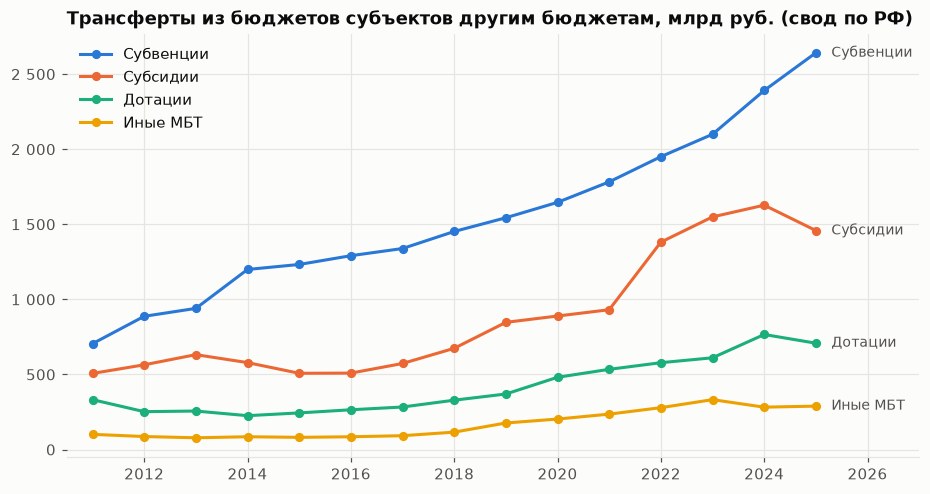

kind,Субвенции,Субсидии,Дотации,Иные МБТ
year,,,,
2011,704.9,506.9,332.1,101.1
2012,887.2,564.1,252.2,86.6
2013,939.9,631.8,256.3,78.3
2014,1 199.1,578.9,225.4,85.1
2015,1 232.4,507.8,243.8,81.2
2016,1 290.8,508.9,264.8,85.0
2017,1 338.5,573.0,283.2,92.2
2018,1 452.0,674.0,328.6,115.8
2019,1 543.5,846.9,369.8,176.8


In [13]:
tr = q("""
SELECT period_year AS year,
       CASE WHEN name ILIKE '%субсидии' THEN 'Субсидии'
            WHEN name ILIKE 'субвенции%' THEN 'Субвенции'
            WHEN name ILIKE 'дотации%' THEN 'Дотации'
            WHEN name ILIKE 'иные межбюджетные трансферты%' THEN 'Иные МБТ' END AS kind,
       sum(value) / 1e9 AS bn
FROM v_value
WHERE territory_code = '95' AND is_preferred AND period_months = 12 AND section = 'settlements'
  AND budget_level = 'total' AND group_name ILIKE 'бюджет субъекта%'
GROUP BY ALL HAVING kind IS NOT NULL ORDER BY 1
""").pivot(index="year", columns="kind", values="bn")[["Субвенции", "Субсидии", "Дотации", "Иные МБТ"]]

fig, ax = plt.subplots()
for i, col in enumerate(tr.columns):
    ax.plot(tr.index, tr[col], color=SERIES[i], marker="o", label=col)
end_labels(ax, [(tr.index[-1] + 0.3, tr[col].iloc[-1], col) for col in tr.columns])
ax.set_xlim(tr.index.min() - 0.5, tr.index.max() + 2)
fmt_axis(ax)
ax.set_title("Трансферты из бюджетов субъектов другим бюджетам, млрд руб. (свод по РФ)")
ax.legend(loc="upper left")
plt.show()
tr

## 10. Сравнение регионов-лидеров

Рост доходов консолидированных бюджетов крупнейших регионов, индекс 2012 = 100 (общая база
вместо второй оси).

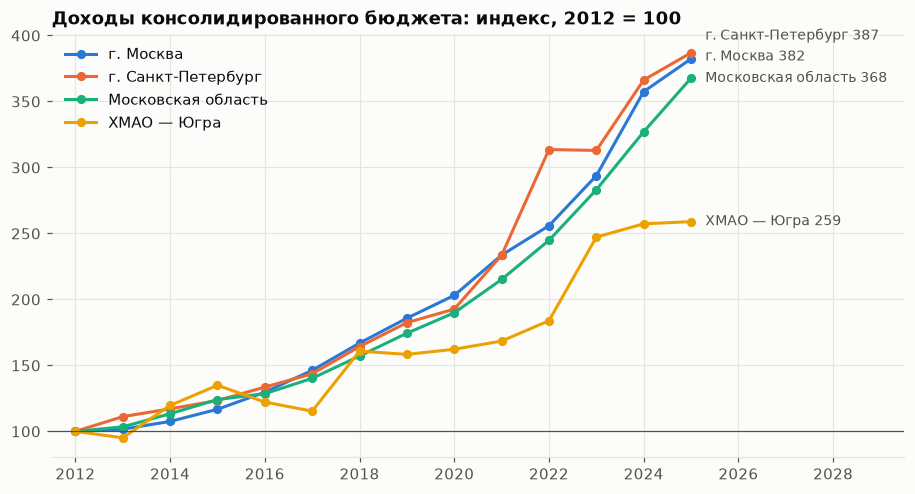

territory_code,73,72,48,87
year,,,,
2012,1 566.5,407.8,492.3,223.2
2013,1 592.6,453.2,509.1,212.3
2014,1 684.4,477.5,558.0,267.1
2015,1 828.6,503.0,611.1,301.1
2016,2 031.6,544.6,632.8,272.8
2017,2 291.0,585.7,690.1,257.4
2018,2 614.6,669.8,773.5,358.9
2019,2 909.9,743.7,858.4,353.4
2020,3 180.6,785.6,934.7,362.1


In [14]:
LEADERS = {"73": "г. Москва", "72": "г. Санкт-Петербург", "48": "Московская область", "87": "ХМАО — Югра"}
ld = q(f"""
SELECT period_year AS year, territory_code, income_executed AS income
FROM v_0503317_totals
WHERE period_months = 12 AND period_year >= 2012 AND territory_code IN ({", ".join(repr(k) for k in LEADERS)})
ORDER BY 1
""").pivot(index="year", columns="territory_code", values="income")[list(LEADERS)]
idx = 100 * ld / ld.iloc[0]

fig, ax = plt.subplots()
for i, code_ in enumerate(idx.columns):
    ax.plot(idx.index, idx[code_], color=SERIES[i], marker="o", label=LEADERS[code_])
end_labels(ax, [(idx.index[-1] + 0.3, idx[c].iloc[-1], f"{LEADERS[c]} {idx[c].iloc[-1]:.0f}") for c in idx.columns])
ax.axhline(100, color=TEXT2, linewidth=0.8)
ax.set_xlim(idx.index.min() - 0.5, idx.index.max() + 4.5)
ax.set_title("Доходы консолидированного бюджета: индекс, 2012 = 100")
ax.legend(loc="upper left")
plt.show()
(ld / 1e9).round(1)

## 11. Данные до 2005 года

До 2005 г. отчёт составлялся по ф. 0524100 (альбом форм, «форма 623») в старой бюджетной
классификации, суммы — в тыс. руб. (в БД пересчитаны в рубли). Графы: назначено и исполнено по
консолидированному бюджету, бюджету субъекта и местным бюджетам (`local_total`). С рядами после
2005 г. эти данные напрямую не сопоставимы: другая классификация доходов и расходов.

In [15]:
q("""
SELECT period_year AS year, territory_code, name, line_code, budget_level, round(value / 1e9, 1) AS bn
FROM v_value
WHERE form_code = '0524100' AND territory_code = '95' AND is_preferred AND period_months = 12
  AND measure = 'executed' AND name ILIKE 'налоговые доходы%'
ORDER BY 1, budget_level
""")

,year,territory_code,name,line_code,budget_level,bn
0,2000,95,НАЛОГОВЫЕ ДОХОДЫ,01,cons_subject,729.7
1,2000,95,НАЛОГОВЫЕ ДОХОДЫ,01,local_total,308.4
2,2000,95,НАЛОГОВЫЕ ДОХОДЫ,01,subject,421.3
3,2001,95,НАЛОГОВЫЕ ДОХОДЫ,01,cons_subject,859.6
4,2001,95,НАЛОГОВЫЕ ДОХОДЫ,01,local_total,343.6
5,2001,95,НАЛОГОВЫЕ ДОХОДЫ,01,subject,516.0
6,2002,95,НАЛОГОВЫЕ ДОХОДЫ,01,local_total,378.9
7,2002,95,НАЛОГОВЫЕ ДОХОДЫ,01,subject,710.1
8,2003,95,НАЛОГОВЫЕ ДОХОДЫ,01,cons_subject,1 341.1
9,2003,95,НАЛОГОВЫЕ ДОХОДЫ,01,local_total,447.3


## 12. Проверки качества и происхождение цифр

**Свод против суммы субъектов.** Сводный отчёт по РФ (код 95) должен совпадать с суммой отчётов
субъектов — это проверка полноты разбора.

In [16]:
chk = q("""
WITH s AS (
    SELECT report_date,
           sum(income_executed)  FILTER (WHERE territory_code <> '95') AS income_subjects,
           max(income_executed)  FILTER (WHERE territory_code =  '95') AS income_svod,
           sum(expense_executed) FILTER (WHERE territory_code <> '95') AS expense_subjects,
           max(expense_executed) FILTER (WHERE territory_code =  '95') AS expense_svod
    FROM v_0503317_totals GROUP BY report_date
)
SELECT year(report_date) AS year, count(*) AS dates, count(income_svod) AS with_svod,
       count(*) FILTER (WHERE abs(income_svod - income_subjects) <= 1 AND abs(expense_svod - expense_subjects) <= 1) AS exact,
       max(abs(income_svod - income_subjects)) AS max_income_diff_rub
FROM s WHERE report_date >= DATE '2012-01-01'
GROUP BY 1 ORDER BY 1
""")
chk

,year,dates,with_svod,exact,max_income_diff_rub
0,2012,12,12,12,0.0
1,2013,12,12,12,0.0
2,2014,12,12,12,0.0
3,2015,12,12,12,0.0
4,2016,12,12,12,0.0
5,2017,12,12,11,51 230.0
6,2018,12,12,12,0.0
7,2019,12,12,12,0.0
8,2020,12,12,12,0.0
9,2021,12,12,12,0.0


**Происхождение значения.** Любое значение прослеживается до листа и строки Excel, файла внутри
пакета и URL пакета на портале.

In [17]:
q("""
SELECT v.value, v.measure, v.budget_level, i.name, l.sheet_name, l.row_no,
       r.member_path, f.url, f.sha256
FROM value v
JOIN line l USING (line_id)
JOIN indicator i USING (indicator_id)
JOIN report r ON r.report_id = v.report_id
JOIN source_file f ON f.package_no = r.package_no
WHERE r.territory_code = '01' AND r.report_date = DATE '2026-08-01' AND r.form_code = '0503317'
  AND i.section = 'expense' AND i.is_total_marker AND i.name ILIKE 'расходы%'
  AND v.measure = 'approved' AND v.budget_level = 'cons_subject_tgvf'
""").T

,0
value,532 023 698 218.6
measure,approved
budget_level,cons_subject_tgvf
name,Расходы бюджета - всего
sheet_name,0503317_Р
row_no,5
member_path,ф. 0503317_01.08.2026_по ФО+Свод Excel .zip/01_01.08.2026_0503317.XLS
url,https://roskazna.gov.ru/storage/page-files/512/%D0%9A%D0%91%D0%A1%D0%A0%D0%A...
sha256,5cce5824bd5cf3d5506c013f47da579e3c61336b917f09782fe05c83d5cef7ee


Это контрольное значение из описания источника в базе знаний «Открытые госфинансы»:
назначения по расходам Республики Башкортостан на 01.08.2026 — 532 023 698 218,57 руб.

## 13. Те же данные из Parquet

Команда `python -m roskazna_kbs export` выгружает таблицы в `data/export/`: факты — с разбиением по
форме и году (`value/form_code=…/report_year=…`). Parquet читается без файла БД — DuckDB, pandas, Polars, Spark.
Пример: исполнение НДФЛ бюджетами субъектов на 1 сентября 2026 г., 10 крупнейших.

In [18]:
EXP = ROOT / "data" / "export"
P = str(EXP) + "/{table}/form_code=0503317/report_year=2026/*.parquet"
duckdb.sql(f"""
SELECT t.name AS territory, sum(v.value) / 1e9 AS ndfl_bn
FROM read_parquet('{P.format(table="value")}') v
JOIN read_parquet('{P.format(table="line")}') l USING (line_id)
JOIN read_parquet('{EXP}/indicator.parquet') i USING (indicator_id)
JOIN read_parquet('{EXP}/report.parquet') r ON r.report_id = v.report_id
JOIN read_parquet('{EXP}/territory.parquet') t ON t.territory_code = r.territory_code
WHERE r.report_date = DATE '2026-09-01' AND r.territory_code <> '95'
  AND i.kbk_code = '10102000010000110'          -- НДФЛ
  AND v.measure = 'executed' AND v.budget_level = 'subject'
GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""").df()

,territory,ndfl_bn
0,г. Москва,1 587.7
1,г. Санкт-Петербург,412.6
2,Московская область,298.5
3,Свердловская область,114.7
4,Республика Татарстан,103.0
5,Краснодарский край,96.3
6,Красноярский край,80.7
7,Нижегородская область,76.4
8,Новосибирская область,67.4
9,Челябинская область,65.9
